In [14]:
import pandas as pd

data_dir = 'data/'

colors = pd.read_parquet(data_dir + 'colors.parquet', engine='pyarrow')

In [15]:
colors.columns

Index(['mpc_designation', 'permid', 'provid', 'obstime_first', 'obstime_last',
       'H_u', 'H_g', 'H_r', 'H_i', 'H_z', 'H_y', 'Herr_u', 'Herr_g', 'Herr_r',
       'Herr_i', 'Herr_z', 'Herr_y', 'Hstd_u', 'Hstd_g', 'Hstd_r', 'Hstd_i',
       'Hstd_z', 'Hstd_y', 'N_u', 'N_g', 'N_r', 'N_i', 'N_z', 'N_y', 'u-g',
       'g-r', 'r-i', 'i-z', 'z-y'],
      dtype='object')

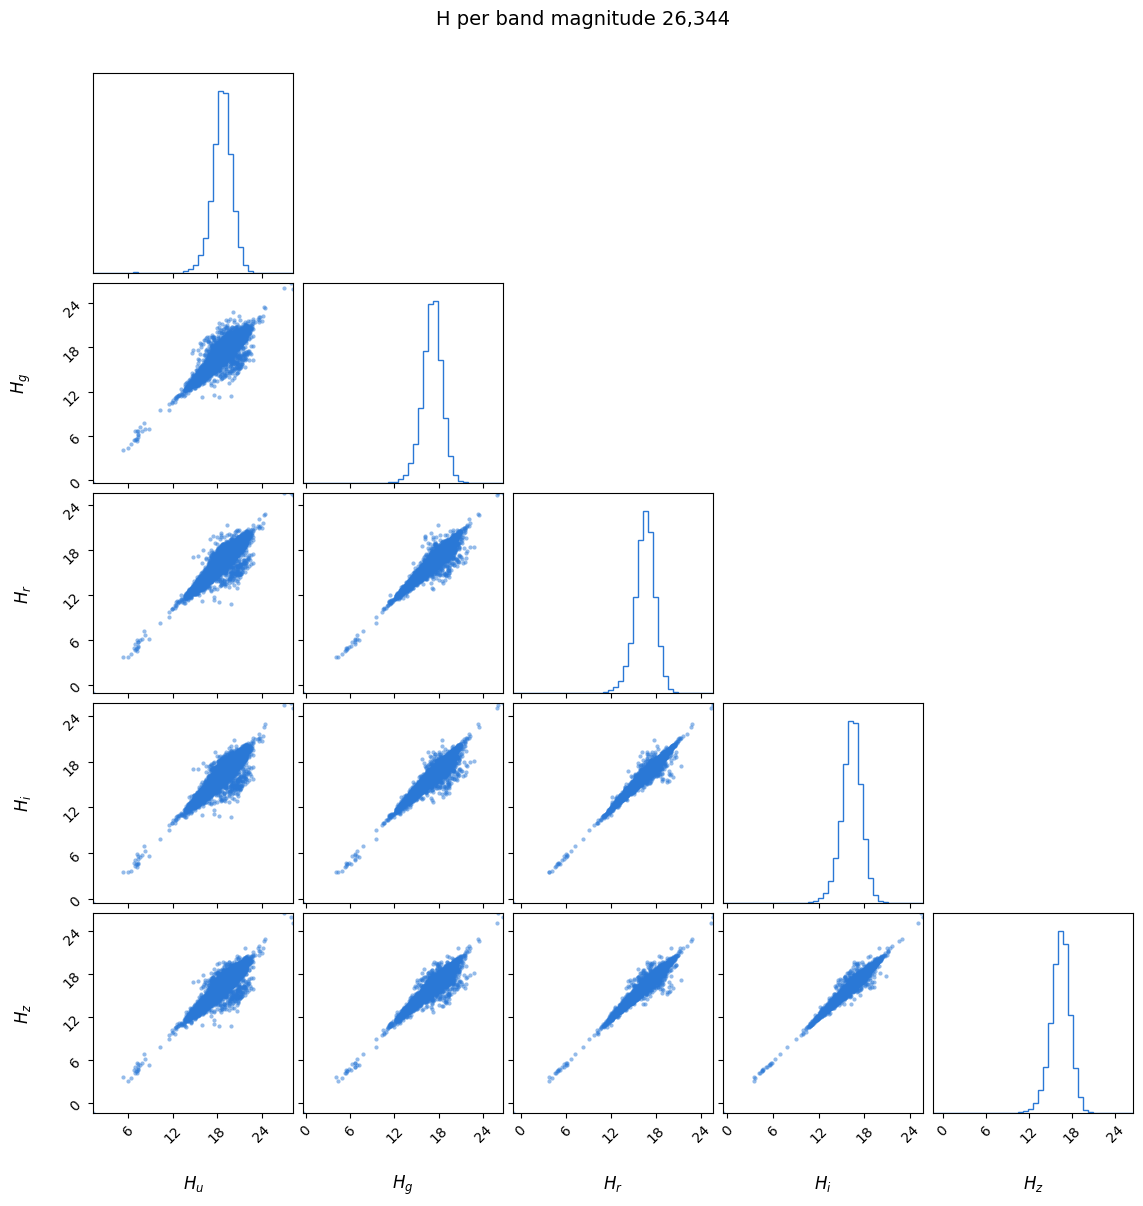

In [16]:
import corner
import matplotlib.pyplot as plt

mag_bands = colors[['H_u', 'H_g', 'H_r', 'H_i', 'H_z']].dropna().astype(float).to_numpy()

mag_labels = [r'$H_u$', r'$H_g$', r'$H_r$', r'$H_i$', r'$H_z$']
fig = corner.corner(mag_bands, labels=mag_labels, bins=40,   # each axis: central 99.5%
                    color='#2a78d6', label_kwargs=dict(fontsize=12),
                    # scatter: one point per NEO, no density contours
                    plot_datapoints=True, plot_density=False, plot_contours=False,
                    data_kwargs=dict(alpha=0.5, ms=3))
fig.suptitle(f'H per band magnitude {len(mag_bands):,}', fontsize=14, y=1.02)

# Save as PNG (bbox_inches='tight' keeps the title, which sits above the axes)
import os
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/h_mag_corner_plot.png', dpi=200, bbox_inches='tight')
plt.show()

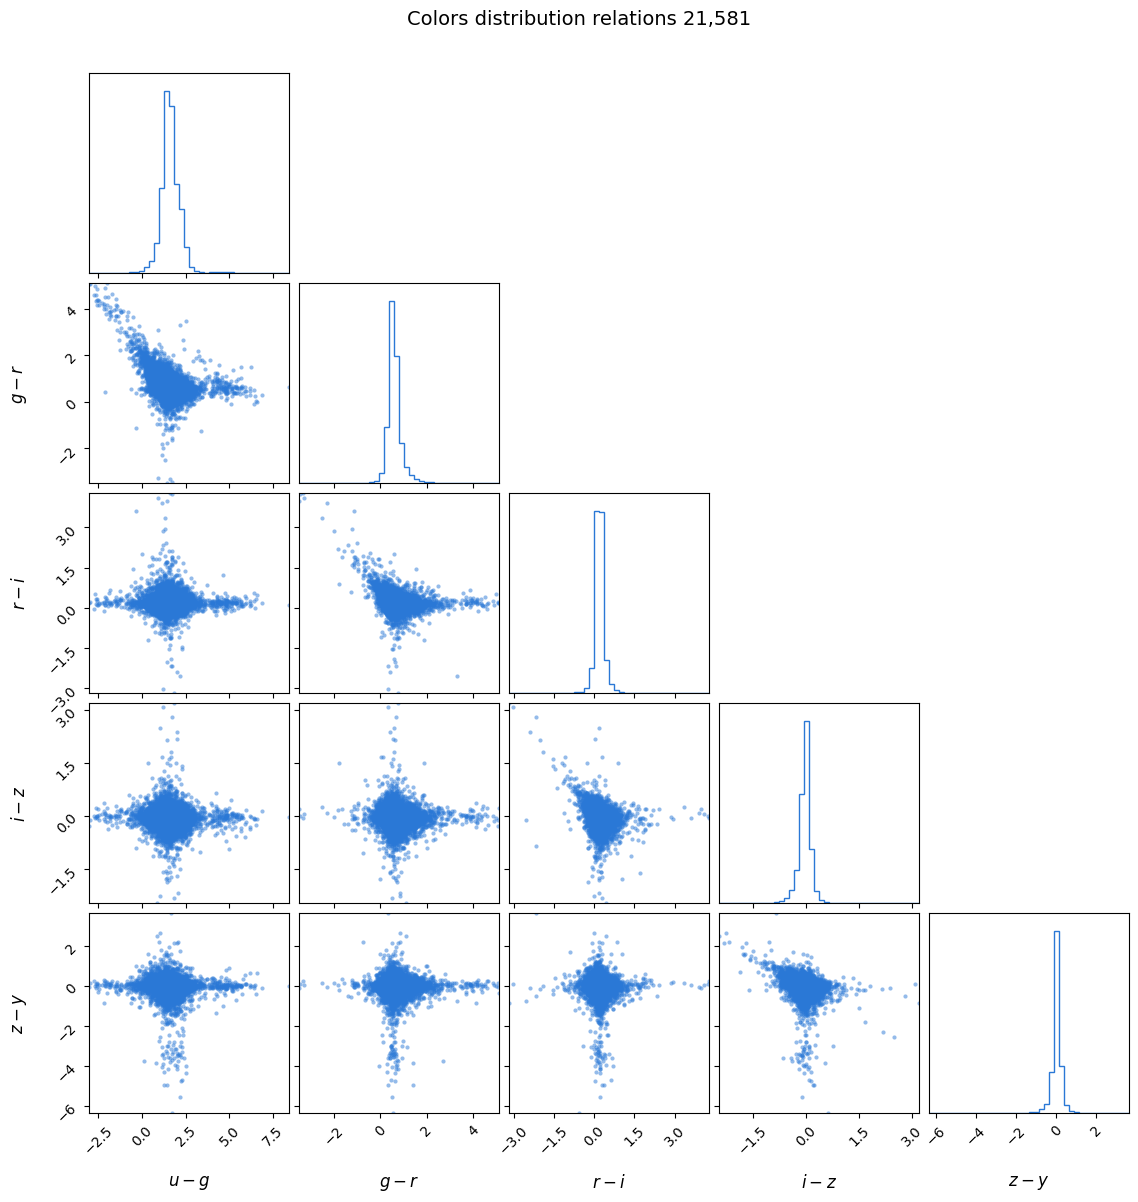

In [17]:
colors_bands = colors[['u-g', 'g-r', 'r-i', 'i-z', 'z-y']].dropna().astype(float).to_numpy()

colors_labels = [r'$u-g$', r'$g-r$', r'$r-i$', r'$i-z$', r'$z-y$']
fig = corner.corner(colors_bands, labels=colors_labels, bins=40,   # each axis: central 99.5%
                    color='#2a78d6', label_kwargs=dict(fontsize=12),
                    # scatter: one point per NEO, no density contours
                    plot_datapoints=True, plot_density=False, plot_contours=False,
                    data_kwargs=dict(alpha=0.5, ms=3))
fig.suptitle(f'Colors distribution relations {len(colors_bands):,}', fontsize=14, y=1.02)

# Save as PNG (bbox_inches='tight' keeps the title, which sits above the axes)
import os
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/colors_corner_plot.png', dpi=200, bbox_inches='tight')
plt.show()

In [18]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

complete = pd.read_csv('medellin-vroc.csv')
fig_dir = 'figures/'
os.makedirs(fig_dir, exist_ok=True)

# Colors: g-r and r-i exist for (almost) every object, u-g for ~40% of them;
# i-z and z-y are left out (fewer than 100 objects, and very noisy)
COLORS = {'u-g': r'$u-g$', 'g-r': r'$g-r$', 'r-i': r'$r-i$'}

# Amplitudes of the light-curve fits (all kinds): column -> (label, plot color)
AMPLITUDES = {
    'amp_photo_k': (r'$A_{\rm photo}$', '#2a78d6'),
    'amp_lsm_k':   (r'$A_{\rm LSM}$',   '#eb6834'),
    'amp_sph_k':   (r'$A_{\rm sph}$',   '#1baf7a'),
    'amp_ell_k':   (r'$A_{\rm ell}$',   '#eda100'),
}

# Adopted rotation period [h]
PERIOD = 'p_rot_multi_used_h'
SPIN_BARRIER = 2.2   # h, rubble-pile spin barrier

# Some fits give unphysical amplitudes (amp_lsm_k reaches ~25,000 mag);
# real asteroid amplitudes stay below ~2 mag, so larger values are masked
AMP_MAX = 2.0
amps = complete[list(AMPLITUDES)].astype(float)
print('Amplitudes masked (> {} mag):'.format(AMP_MAX), (amps > AMP_MAX).sum().to_dict())
amps = amps.where(amps <= AMP_MAX)

period = complete[PERIOD].astype(float)
print(f'{len(complete):,} asteroids, {period.notna().sum():,} with a rotation period')


def relation(ax, x, y, color):
    """Scatter y vs x (rows with both values) and print N and the Spearman correlation."""
    ok = x.notna() & y.notna()
    ax.scatter(x[ok], y[ok], s=14, alpha=0.6, color=color, edgecolor='none')
    rho = spearmanr(x[ok], y[ok])[0]
    ax.text(0.97, 0.95, f'N = {ok.sum()}\n' + r'$\rho_s$' + f' = {rho:.2f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color='0.25',
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.8', alpha=0.9), zorder=5)
    ax.grid(True, which='both', color='0.9', lw=0.6)
    ax.set_axisbelow(True)


def spin_barrier(ax):
    ax.axvline(SPIN_BARRIER, color='0.4', ls='--', lw=1)
    ax.text(SPIN_BARRIER, 0.02, f' {SPIN_BARRIER} h', transform=ax.get_xaxis_transform(),
            va='bottom', ha='left', fontsize=9, color='0.3')

Amplitudes masked (> 2.0 mag): {'amp_photo_k': 2, 'amp_lsm_k': 30, 'amp_sph_k': 0, 'amp_ell_k': 3}
524 asteroids, 524 with a rotation period


In [19]:
complete[list(COLORS) + list(AMPLITUDES) + [PERIOD]].describe().T

,count,mean,std,min,25%,50%,75%,max
u-g,206.0,1.094371,0.479506,-0.850606,0.861590,1.223934,1.427093,1.738277
g-r,523.0,0.531362,0.087296,0.326528,0.457307,0.532080,0.599317,0.815003
r-i,524.0,0.162436,0.056185,-0.087370,0.126766,0.166057,0.195208,0.356491
amp_photo_k,524.0,0.688874,0.462949,0.134034,0.425847,0.682080,0.900975,8.678532
amp_lsm_k,524.0,77.360599,1236.648108,0.017576,0.288066,0.511785,0.769651,25114.371088
amp_sph_k,524.0,0.421581,0.232827,0.024007,0.214957,0.380957,0.662940,0.752558
amp_ell_k,524.0,0.471698,0.336370,0.028782,0.240275,0.425789,0.648195,3.252573
p_rot_multi_used_h,524.0,8.347169,8.935976,0.049867,3.753057,5.615365,8.397967,46.656739


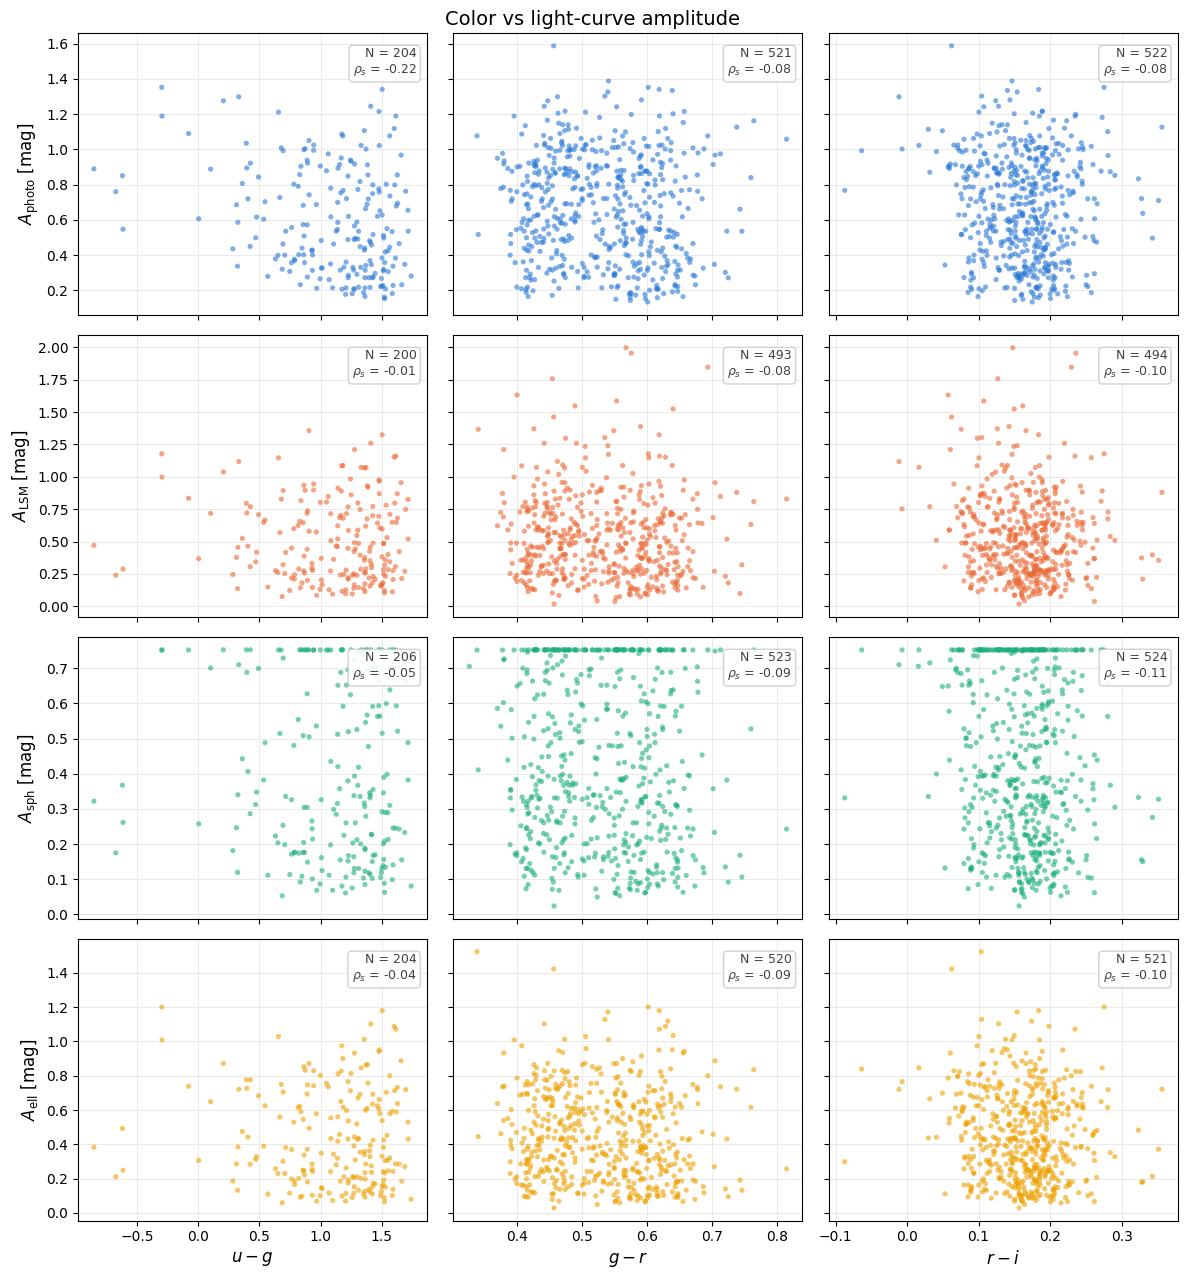

In [20]:
# Color - amplitude: one row per kind of amplitude, one column per color
fig, axes = plt.subplots(len(AMPLITUDES), len(COLORS), figsize=(12, 13),
                         sharex='col', sharey='row')

for i, (amp, (amp_label, color)) in enumerate(AMPLITUDES.items()):
    for j, (col, col_label) in enumerate(COLORS.items()):
        ax = axes[i, j]
        relation(ax, complete[col].astype(float), amps[amp], color)
        if i == len(AMPLITUDES) - 1:
            ax.set_xlabel(col_label, fontsize=12)
        if j == 0:
            ax.set_ylabel(f'{amp_label} [mag]', fontsize=12)

fig.suptitle('Color vs light-curve amplitude', fontsize=14)
fig.tight_layout()
fig.savefig(fig_dir + 'color_amplitude.png', dpi=200, bbox_inches='tight')
plt.show()

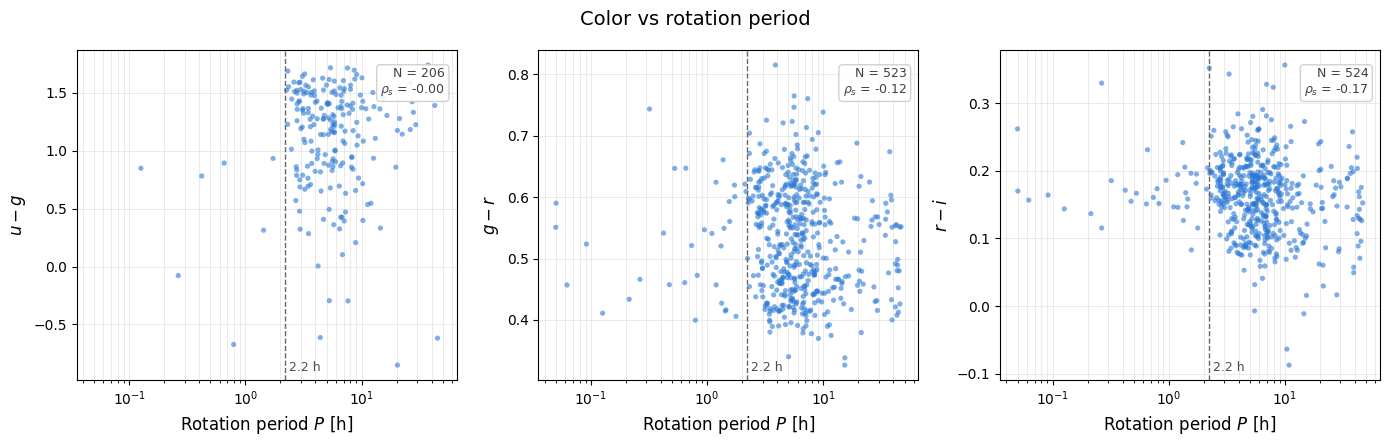

In [21]:
# Color - period: one panel per color
fig, axes = plt.subplots(1, len(COLORS), figsize=(14, 4.5), sharex=True)

for ax, (col, col_label) in zip(axes, COLORS.items()):
    relation(ax, period, complete[col].astype(float), '#2a78d6')
    spin_barrier(ax)
    ax.set_xscale('log')
    ax.set_xlabel(r'Rotation period $P$ [h]', fontsize=12)
    ax.set_ylabel(col_label, fontsize=12)

fig.suptitle('Color vs rotation period', fontsize=14)
fig.tight_layout()
fig.savefig(fig_dir + 'color_period.png', dpi=200, bbox_inches='tight')
plt.show()

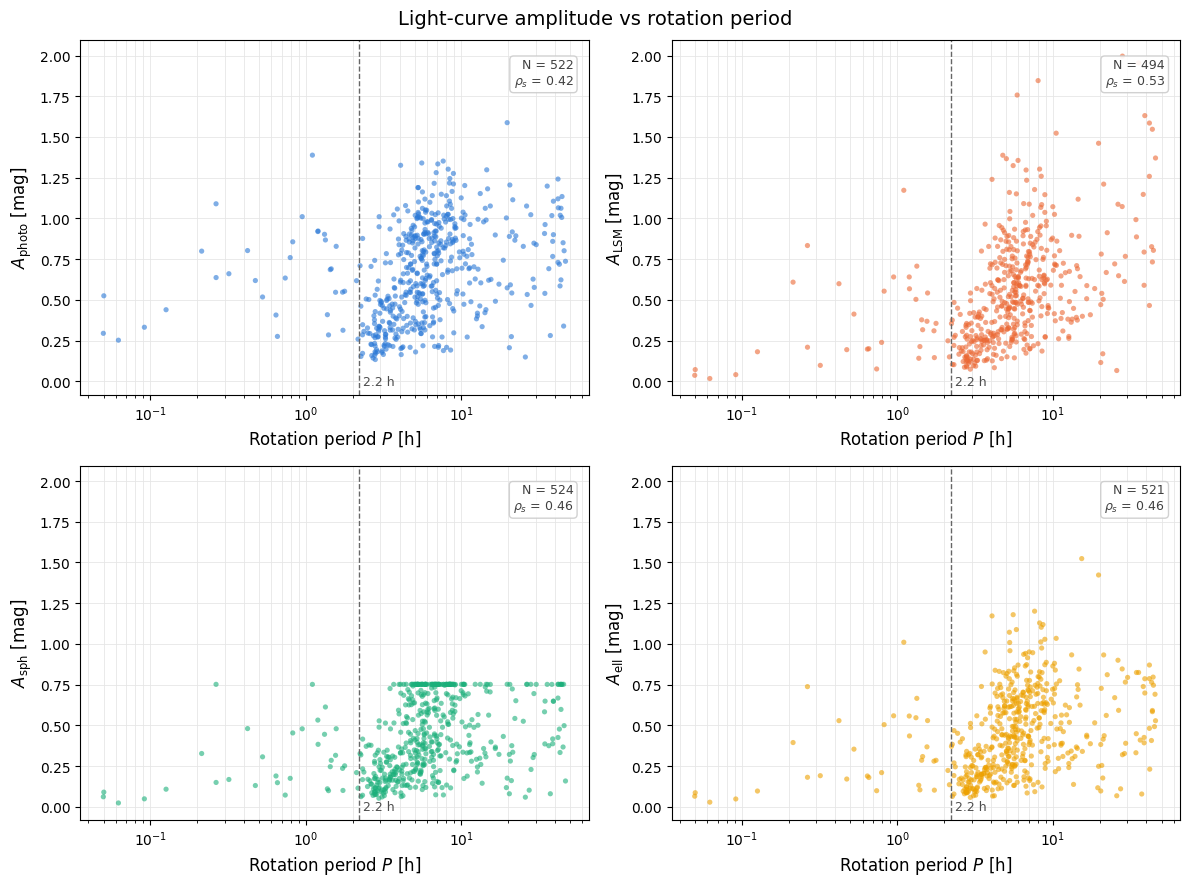

In [22]:
# Amplitude - period: one panel per kind of amplitude
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)

for ax, (amp, (amp_label, color)) in zip(axes.flat, AMPLITUDES.items()):
    relation(ax, period, amps[amp], color)
    spin_barrier(ax)
    ax.set_xscale('log')
    ax.set_xlabel(r'Rotation period $P$ [h]', fontsize=12)
    ax.set_ylabel(f'{amp_label} [mag]', fontsize=12)
    ax.tick_params(labelleft=True, labelbottom=True)

fig.suptitle('Light-curve amplitude vs rotation period', fontsize=14)
fig.tight_layout()
fig.savefig(fig_dir + 'amplitude_period.png', dpi=200, bbox_inches='tight')
plt.show()